In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## error-bar-plot

**Figure 2: GLUE accuracy of five fine-tuning methods, averaged over 5 seeds.** Error bars show ±1 std over 5 seeds; the dashed line marks full fine-tuning's mean. Ours reaches 0.879, 0.014 above full fine-tuning (0.865), about three times the seed std of either method (≤0.0046).

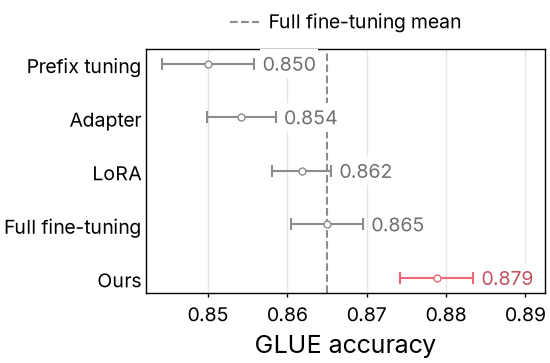

In [2]:
with open("../data/error-bar-plot.json") as f:
    runs = json.load(f)["accuracy_per_seed"]

methods = sorted(runs, key=lambda m: np.mean(runs[m]))

fig, ax = plt.subplots(figsize=(2.75, 2))
ax.axvline(np.mean(runs["Full fine-tuning"]), linestyle="--", linewidth=paper.dashed_width, color=colors["neutral"],
           zorder=1, label="Full fine-tuning mean")
for y, method in enumerate(methods):
    color = colors["ours"] if method == "Ours" else colors["neutral"]
    mean, std = np.mean(runs[method]), np.std(runs[method], ddof=1)
    ax.errorbar(mean, y, xerr=std, fmt="o", color=color, capsize=2, elinewidth=0.75, capthick=0.75)
    ax.annotate(f"{mean:#.3g}", (mean + std, y), xytext=(3, 0), textcoords="offset points",
                ha="left", va="center", color=darken(color),
                bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.set_yticks(range(len(methods)), labels=methods)
ax.invert_yaxis()
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:g}".replace("-", "−"))
ax.set_xlabel("GLUE accuracy")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), borderaxespad=0.5, frameon=False)

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/error-bar-plot.pdf")
fig.savefig("../outputs/error-bar-plot.png")
plt.show()